In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly as plotly



## Latency 1:1

   emisor  paquete  mensaje  latencia_1_ms  latencia_2_ms  latencia_3_ms  \
0       7        1        1          1.563          1.428          1.561   
1       7        2        1          1.509          1.388          1.453   
2       7        2        2          1.425          1.373          1.368   
3       7        3        1          1.597          1.549          1.630   
4       7        3        2          1.497          1.520          1.491   

   latencia_4_ms  latencia_5_ms  
0         -0.038         -0.223  
1          0.054         -0.125  
2          0.058         -0.151  
3          0.012          0.216  
4          0.150          0.141  


<Axes: title={'center': 'Latencia promedio por paquete'}, xlabel='paquete'>

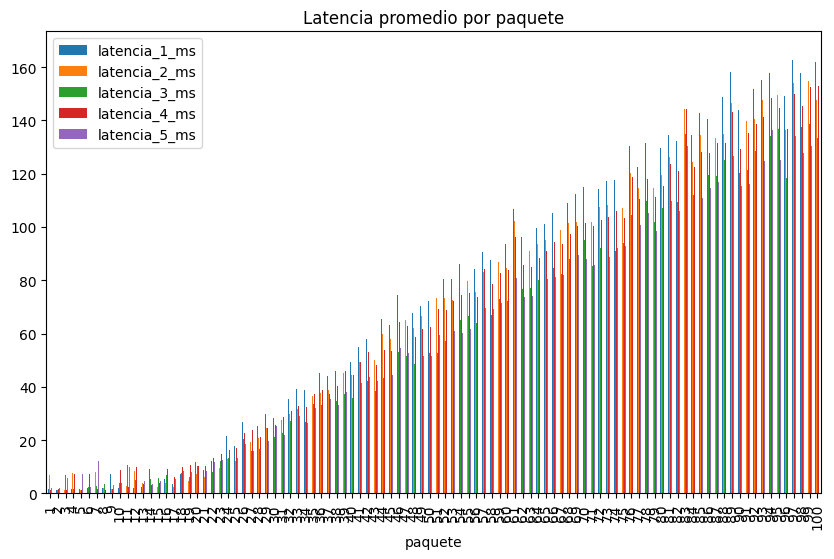

In [29]:
# datos1 = pd.read_csv('receptor/datos1.csv')
# datos2 = pd.read_csv('receptor/datos2.csv')
# datos3 = pd.read_csv('receptor/datos3.csv')
# datos4 = pd.read_csv('receptor/datos4.csv')
# datos5 = pd.read_csv('receptor/datos5.csv')

datos1 = pd.read_csv('datasets/opentwins-agent-receptor-7-66648bc4c8-vd5xs_dataset_mensajes_7_5.csv')
datos2 = pd.read_csv('datasets/opentwins-agent-receptor-12-75df99f994-7lwm7_dataset_mensajes_12_5.csv')
datos3 = pd.read_csv('datasets/opentwins-agent-receptor-24-79c75d564-g848x_dataset_mensajes_24_5.csv')
datos4 = pd.read_csv('datasets/opentwins-agent-receptor-32-66b489866-psfsj_dataset_mensajes_32_5.csv')
datos5 = pd.read_csv('datasets/opentwins-agent-receptor-45-859c65f5b6-r4vk2_dataset_mensajes_45_5.csv')

datos1["timestamp"] = pd.to_datetime(datos1["timestamp"], format="ISO8601")
datos1["timestamp_llegada"] = pd.to_datetime(datos1["timestamp_llegada"], format="ISO8601")
datos2["timestamp"] = pd.to_datetime(datos2["timestamp"], format="ISO8601")
datos2["timestamp_llegada"] = pd.to_datetime(datos2["timestamp_llegada"], format="ISO8601")
datos3["timestamp"] = pd.to_datetime(datos3["timestamp"], format="ISO8601")
datos3["timestamp_llegada"] = pd.to_datetime(datos3["timestamp_llegada"], format="ISO8601")
datos4["timestamp"] = pd.to_datetime(datos4["timestamp"], format="ISO8601")
datos4["timestamp_llegada"] = pd.to_datetime(datos4["timestamp_llegada"], format="ISO8601")
datos5["timestamp"] = pd.to_datetime(datos5["timestamp"], format="ISO8601")
datos5["timestamp_llegada"] = pd.to_datetime(datos5["timestamp_llegada"], format="ISO8601")


datos1["latencia_1_ms"] = (datos1["timestamp_llegada"] - datos1["timestamp"]).dt.total_seconds()*1000
datos2["latencia_2_ms"] = (datos2["timestamp_llegada"] - datos2["timestamp"]).dt.total_seconds()*1000
datos3["latencia_3_ms"] = (datos3["timestamp_llegada"] - datos3["timestamp"]).dt.total_seconds()*1000
datos4["latencia_4_ms"] = (datos4["timestamp_llegada"] - datos4["timestamp"]).dt.total_seconds()*1000
datos5["latencia_5_ms"] = (datos5["timestamp_llegada"] - datos5["timestamp"]).dt.total_seconds()*1000

datos1.drop(columns=["timestamp", "timestamp_llegada"], inplace=True)
datos2.drop(columns=["timestamp", "timestamp_llegada"], inplace=True)
datos3.drop(columns=["timestamp", "timestamp_llegada"], inplace=True)
datos4.drop(columns=["timestamp", "timestamp_llegada"], inplace=True)
datos5.drop(columns=["timestamp", "timestamp_llegada"], inplace=True)

# We get the average latency of the 5 datasets
df = datos1
df["latencia_2_ms"] = datos2["latencia_2_ms"]
df["latencia_3_ms"] = datos3["latencia_3_ms"]
df["latencia_4_ms"] = datos4["latencia_4_ms"]
df["latencia_5_ms"] = datos5["latencia_5_ms"]


print(df.head())

df.groupby("paquete").mean().plot(kind="bar", y=["latencia_1_ms", "latencia_2_ms", "latencia_3_ms", "latencia_4_ms", "latencia_5_ms"], figsize=(10, 6), title="Latencia promedio por paquete")

### Latency m:m

In [14]:
# Read all csv files in dataset folder and concatenate them into a single dataframe
import os
dataset_folder = "datasets"
all_files = [os.path.join(dataset_folder, f) for f in os.listdir(dataset_folder) if f.endswith(".csv")]
df = pd.concat((pd.read_csv(f) for f in all_files))
df.to_csv("datasets/one_to_rfule_them_all.csv.gz")


In [53]:
df = pd.read_csv("datasets/one_to_rfule_them_all.csv.gz")
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["timestamp_llegada"] = pd.to_datetime(df["timestamp_llegada"])
df["latencia_ms"] = (df["timestamp_llegada"] - df["timestamp"]).dt.total_seconds()*1000
df.drop(columns=["timestamp", "timestamp_llegada"], inplace=True)
df = df[df["paquete"].isin([1,10,20,30,40,50, 60,70,80,90,100])]
# df = df.groupby("paquete").mean()

print(df.head())



    Unnamed: 0  emisor  paquete  mensaje  latencia_ms
0            0       1        1        1        1.421
45          45       1       10        1        1.351
46          46       1       10        2        1.463
47          47       1       10        3        1.514
48          48       1       10        4       45.584


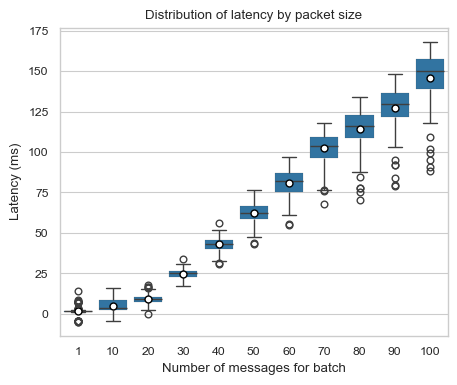

In [ ]:

df = df.groupby(["emisor", "paquete"])["latencia_ms"].mean().reset_index()

plt.figure(figsize=(5, 4))

sns.boxplot(
    data=df,
    x="paquete",
    y="latencia_ms",
    showmeans=True,  # muestra la media
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 5
    },
    boxprops={"linewidth": 0.1},
)

plt.xlabel("Number of messages for batch")
plt.ylabel("Latency (ms)")
plt.title("Distribution of latency by packet size")

# plt.xticks(rotation=45)
# plt.tight_layout()
plt.savefig('figures/latency_message.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()


# fig, ax1 = plt.subplots(figsize=(5, 4))

# # Colors for MAE and MSE
# blue = '#1f77b4'
# orange = '#ff7f0e'

# # Plot MAE (train/val) on left y-axis
# ax1.plot(df.index, df['latencia_ms'], color=blue, linestyle='--', label='Batch of agents deployment')
# ax1.set_xlabel('Group')
# ax1.set_ylabel('Time (ms)')



# # Combine legends
# lines_1, labels_1 = ax1.get_legend_handles_labels()

# ax1.grid(True, linestyle='--', alpha=0.7)

# # Style improvements
# plt.title('Communication Latency between emisor agent and receptor')
# sns.set_style("whitegrid")
# sns.set_context("paper")

# plt.tight_layout()

# # Save figure to PDF
# plt.savefig('figures/deploy_latency.pdf', format='pdf', bbox_inches='tight', dpi=300)

# plt.show()


# df.plot(kind="bar", y=["latencia_ms"], figsize=(10, 6), title="Latencia promedio por paquete")


## Latency deploy

In [5]:
import os
dataset_folder = "datasets_deploy"
all_files = [os.path.join(dataset_folder, f) for f in os.listdir(dataset_folder) if f.endswith(".csv")]
df = pd.concat((pd.read_csv(f) for f in all_files))
df.to_csv("datasets_deploy/one_to_rfule_them_all.csv", index=False)

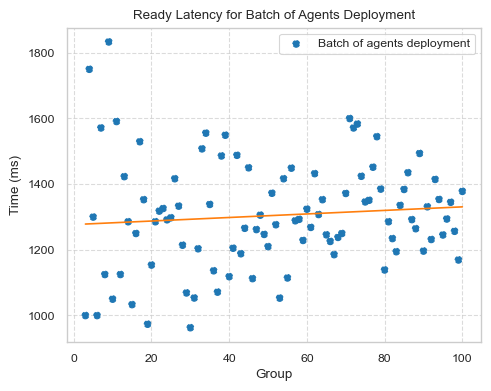

In [55]:
df = pd.read_csv("datasets_deploy/one_to_rfule_them_all.csv")


df["apiTimestamp"] = pd.to_datetime(df["apiTimestamp"], utc=True)
df["creationTimestamp"] = pd.to_datetime(df["creationTimestamp"], utc=True)
df["readyTimestamp"] = pd.to_datetime(df["readyTimestamp"], utc=True)

#df["api_latency_ms"] = (df["creationTimestamp"] - df["apiTimestamp"]).dt.total_seconds()*1000
df["ready_latency_ms"] = (df["readyTimestamp"] - df["creationTimestamp"]).dt.total_seconds()*1000

df.drop(columns=["apiTimestamp", "creationTimestamp", "readyTimestamp", "nombre"], inplace=True)



# df.groupby("grupo").mean().plot(kind="bar", y=["api_latency_ms"], figsize=(10, 6), title="Latencia promedio por paquete")
df = df.groupby("grupo").mean()

# 2. Ajuste lineal (grado 1)
m, b = np.polyfit(df.index, df['ready_latency_ms'], 1)  # m = pendiente, b = intercepto

# 3. Recta de regresión
y_fit = m * df.index + b


fig, ax1 = plt.subplots(figsize=(5, 4))

# Colors for MAE and MSE
blue = '#1f77b4'
orange = '#ff7f0e'

# Plot MAE (train/val) on left y-axis
ax1.scatter(df.index, df['ready_latency_ms'], color=blue, linestyle='--', label='Batch of agents deployment')
ax1.set_xlabel('Group')
ax1.set_ylabel('Time (ms)')

ax1.plot(df.index, y_fit, color=orange)
# Create second y-axis for MSE
# ax2 = ax1.twinx()
# ax2.plot(y_fit, color=orange, linestyle='-')

# Combine legends
lines_1, labels_1 = ax1.get_legend_handles_labels()
ax1.legend(lines_1, labels_1, loc='upper right')

ax1.grid(True, linestyle='--', alpha=0.7)

# Style improvements
plt.title('Ready Latency for Batch of Agents Deployment')
sns.set_style("whitegrid")
sns.set_context("paper")

plt.tight_layout()

# Save figure to PDF
plt.savefig('figures/deploy_latency.pdf', format='pdf', bbox_inches='tight', dpi=300)

plt.show()


# df.plot(kind="bar", y=["ready_latency_ms"], figsize=(10, 6), title="Latencia promedio por paquete")